# CNN, matched filter, and sequential pipeline evaluation

Run `python bin/evaluate_pipeline.py examples/evaluation/simple.json` first.
Set `RUN` below. All three methods use the same injected/control examples and
target splits. Each has precision–recall, a confusion matrix, and an amplitude
sensitivity curve. Controls are benchmark negatives with unknown astrophysical
labels; precision is conditional on this benchmark's class mixture.

CNN amplitude sensitivity measures injected-curve acceptance. Matched-filter and
cascade sensitivity require a detection near the event. The default cascade is
matched filter → CNN, with both gates required. Component scores are computed
once for comparison; sequential survivor counts model the gating, not runtime.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'searchlight').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
RUN = ROOT / 'evaluation_runs/full-evaluation'  # base name; newest completed numbered run is selected
candidates = [RUN, *RUN.parent.glob(RUN.name + '-[0-9][0-9][0-9]*')]
completed = [p for p in candidates if (p / 'complete.json').is_file()]
if completed:
    RUN = max(completed, key=lambda p: (p / 'complete.json').stat().st_mtime_ns)
RESULTS = RUN / 'results'
if not (RUN / 'complete.json').exists():
    raise RuntimeError(f'No completed evaluation at {RUN}; run the bin script first or select a finished run.')
load = lambda name: json.loads((RESULTS / f'{name}.json').read_text())
metrics, scores, events = load('metrics'), load('scores'), load('event_details')
run, sensitivity = load('run'), load('amplitude_recovery')
manifest = load('manifest')
print('Loaded:', RUN)

Loaded: /home/anm1u24/Code/astrosearchlight/evaluation_runs/full-evaluation-002


## Physical parameters of the injected profiles

Corner plots show the **actual saved draws**, counting each target/shape once,
regardless of how many amplitudes were injected. Diagonal panels show counts;
lower panels show individual draws and their pairwise relationships. Colours
separate tuning and test profiles. With this small sample, these are scatter
plots and histograms rather than smoothed density contours.

Plots are split into orbital, stellar, and duration parameters for readability.
Axes marked $\log_{10}$ use base-10 logarithms in the indicated units.
Lens mass is `Macc`; source mass is `Mcomp`. Source radius and temperature follow
the simulator's stellar relations, so their correlations are expected. Local
crossing time and measured exposure-averaged FWHM are distinct quantities.

These draws are conditional on lensing, no Roche-lobe overflow, and an isolated,
adequately sampled event. Source properties are not fitted to the background
star. Physical parameters describe the **unscaled shape**: the final plot shows
how those shapes were multiplied to reach the requested injected amplitudes.
Figures are exported as PNG and PDF under the run's `results` directory.

The full proposal also records distance; distance does not determine the measured
noise of the real background. The run records whether amplitude means the sampled
maximum (pilot) or the reference exposure-averaged peak independent of gaps (full).

New generation draws **both source and lens masses log-uniformly**, before physical rejection. Plots always use the saved run: reusing old injections preserves their original mass distribution.


800 generated target/shape profiles across 100 backgrounds
  test: 600 profiles, 75 backgrounds
  tuning: 200 profiles, 25 backgrounds


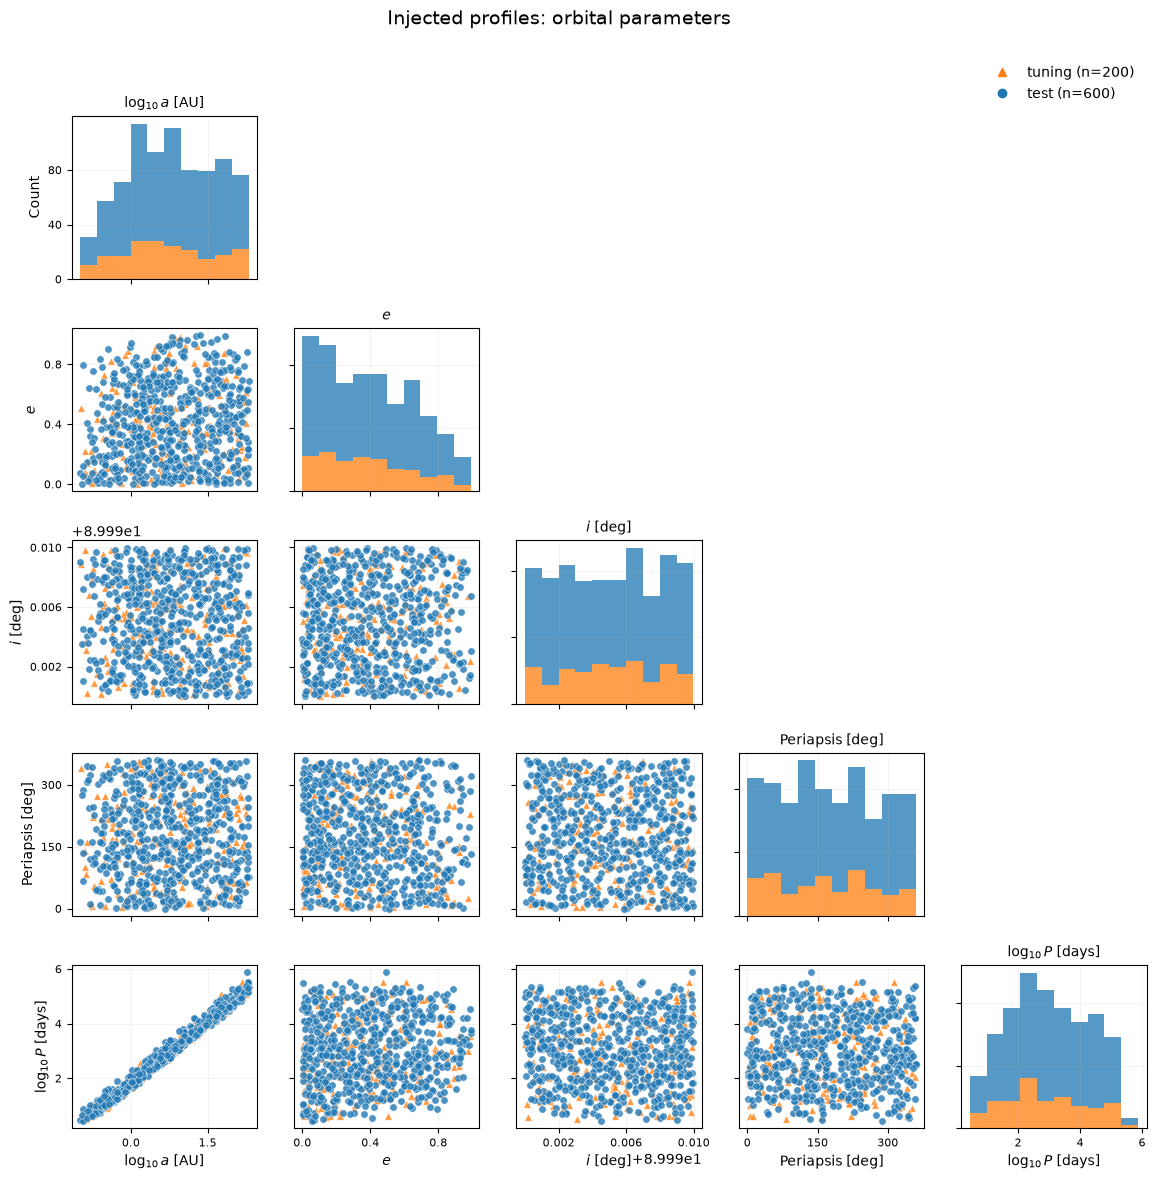

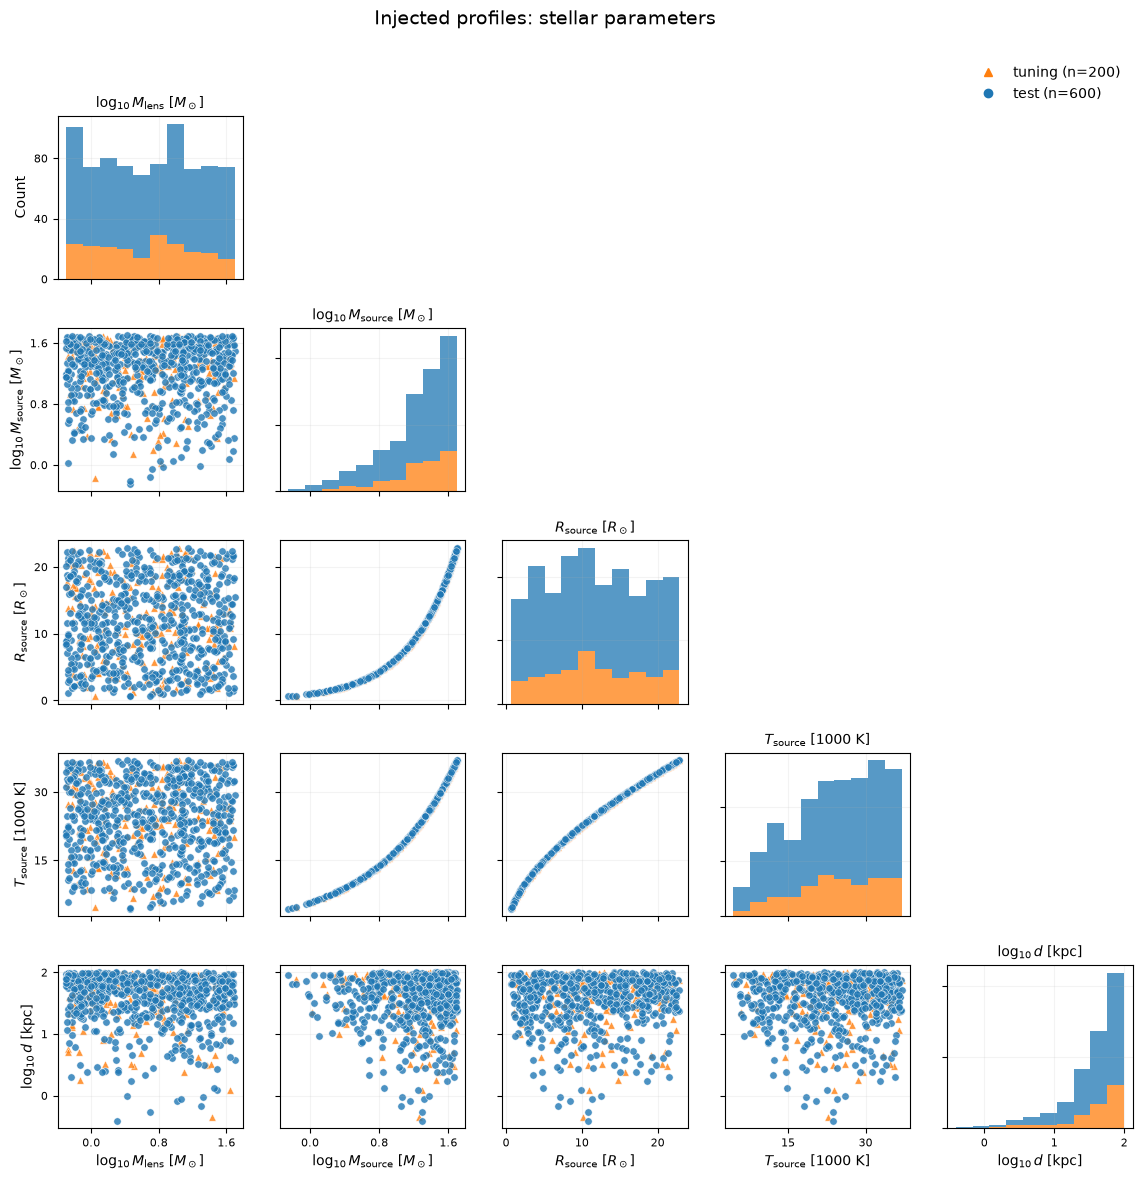

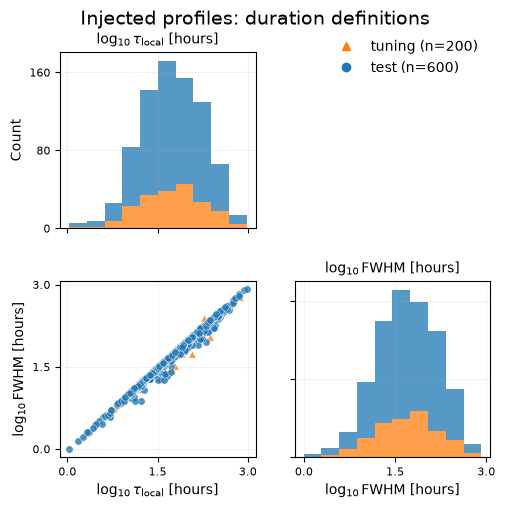

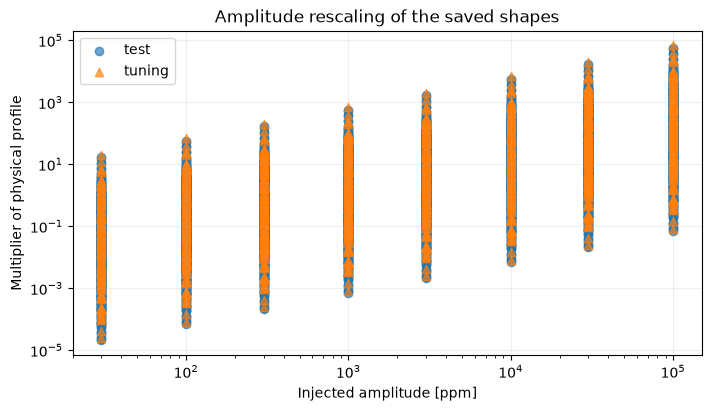

In [2]:
# One row per generated target/shape, not per amplitude variant.
profile_records = manifest.get('metadata', {}).get('profiles', [])
sample_records = {s['sample_id']: s for s in manifest['samples']}
physical_rows = []
for profile in profile_records:
    p = profile['physical_parameters']
    original = sample_records[profile['sample_id']]
    physical_rows.append({
        'background': profile['sample_id'], 'shape': profile['shape'], 'split': original['split'],
        'Semi-major axis (AU)': p['a'], 'Lens mass (solar masses)': p['Macc'],
        'Source mass (solar masses)': p['Mcomp'], 'Source radius (solar radii)': p['Rcomp'],
        'Source temperature (K)': p['Teff'], 'Eccentricity': p['e'],
        'Inclination (deg)': np.degrees(p['i']),
        'Periapsis phase (deg)': np.degrees(p['periapsis_phase']),
        'Orbital period (days)': p['period_days'],
        'Local crossing estimate (hours)': p['duration_days'] * 24,
        **({'Distance (kpc)': p['d']} if 'd' in p else {}),
        'Measured FWHM (hours)': profile['fwhm_days'] * 24,
    })
physical_profiles = pd.DataFrame(physical_rows)
if physical_profiles.empty:
    print('No per-profile physical parameters were saved in this run.')
else:
    print(f"{len(physical_profiles)} generated target/shape profiles across "
          f"{physical_profiles['background'].nunique()} backgrounds")
    for split, group in physical_profiles.groupby('split'):
        print(f"  {split}: {len(group)} profiles, {group['background'].nunique()} backgrounds")


def parameter_corner(frame, columns, labels, title, filename):
    """Counts and raw pairwise draws, without a density estimate for sparse samples."""
    from matplotlib.ticker import MaxNLocator
    from matplotlib.lines import Line2D
    colours = {'tuning': 'tab:orange', 'test': 'tab:blue'}
    markers = {'tuning': '^', 'test': 'o'}
    splits = [split for split in ['tuning', 'test'] if (frame['split'] == split).any()]
    size = len(columns)
    fig, axes = plt.subplots(size, size, figsize=(2.5 * size, 2.5 * size), squeeze=False)
    for i, y in enumerate(columns):
        for j, x in enumerate(columns):
            ax = axes[i, j]
            if j > i:
                ax.set_visible(False)
                continue
            if i == j:
                finite = frame[x].to_numpy(dtype=float)
                finite = finite[np.isfinite(finite)]
                bins = np.histogram_bin_edges(finite, bins=min(10, max(4, int(np.sqrt(len(finite))))))
                ax.hist([frame.loc[frame['split'] == split, x].dropna() for split in splits],
                        bins=bins, stacked=True, color=[colours[split] for split in splits], alpha=.75)
                ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=3))
                ax.set_title(labels[j], fontsize=10)
            else:
                for split in splits:
                    selected = frame[frame['split'] == split]
                    ax.scatter(selected[x], selected[y], color=colours[split], marker=markers[split],
                               s=28, alpha=.8, edgecolors='white', linewidths=.4)
                ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
            ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
            ax.tick_params(labelsize=8, labelbottom=i == size - 1, labelleft=j == 0)
            if i == size - 1:
                ax.set_xlabel(labels[j], fontsize=10)
            if j == 0:
                ax.set_ylabel('Count' if i == j else labels[i], fontsize=10)
            ax.grid(alpha=.15)
    handles = [Line2D([], [], color=colours[split], marker=markers[split], linestyle='',
                      label=f"{split} (n={(frame['split'] == split).sum()})") for split in splits]
    fig.suptitle(title, fontsize=14, y=.995)
    fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(.97, .96), frameon=False)
    fig.subplots_adjust(left=.11, bottom=.10, top=.91, right=.97, hspace=.30, wspace=.20)
    for suffix in ['png', 'pdf']:
        fig.savefig(RESULTS / f'{filename}.{suffix}', dpi=160, bbox_inches='tight')
    plt.show()


if not physical_profiles.empty:
    corner_data = physical_profiles.copy()
    for column in ['Semi-major axis (AU)', 'Lens mass (solar masses)', 'Source mass (solar masses)',
                   'Orbital period (days)', 'Local crossing estimate (hours)', 'Measured FWHM (hours)']:
        corner_data['log ' + column] = np.log10(corner_data[column])
    corner_data['Source temperature (1000 K)'] = corner_data['Source temperature (K)'] / 1000
    parameter_corner(corner_data,
        ['log Semi-major axis (AU)', 'Eccentricity', 'Inclination (deg)',
         'Periapsis phase (deg)', 'log Orbital period (days)'],
        [r'$\log_{10} a$ [AU]', r'$e$', r'$i$ [deg]', 'Periapsis [deg]', r'$\log_{10} P$ [days]'],
        'Injected profiles: orbital parameters', 'parameter_corner_orbits')
    stellar_columns = ['log Lens mass (solar masses)', 'log Source mass (solar masses)',
                       'Source radius (solar radii)', 'Source temperature (1000 K)']
    stellar_labels = [r'$\log_{10} M_\mathrm{lens}$ [$M_\odot$]', r'$\log_{10} M_\mathrm{source}$ [$M_\odot$]',
                      r'$R_\mathrm{source}$ [$R_\odot$]', r'$T_\mathrm{source}$ [1000 K]']
    if 'Distance (kpc)' in corner_data:
        corner_data['log Distance (kpc)'] = np.log10(corner_data['Distance (kpc)'])
        stellar_columns.append('log Distance (kpc)')
        stellar_labels.append(r'$\log_{10} d$ [kpc]')
    parameter_corner(corner_data, stellar_columns, stellar_labels,
        'Injected profiles: stellar parameters', 'parameter_corner_stars')
    parameter_corner(corner_data,
        ['log Local crossing estimate (hours)', 'log Measured FWHM (hours)'],
        [r'$\log_{10} \tau_\mathrm{local}$ [hours]', r'$\log_{10} \mathrm{FWHM}$ [hours]'],
        'Injected profiles: duration definitions', 'parameter_corner_durations')

amplitude_rows = [{
    'split': s['split'], 'amplitude_ppm': s['parameters']['amplitude'] * 1e6,
    'profile_multiplier': s['parameters']['amplitude_scale'],
} for s in manifest['samples'] if s.get('parent_id') and 'amplitude_scale' in s['parameters']]
if amplitude_rows:
    amplitude_data = pd.DataFrame(amplitude_rows)
    fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
    for split, group in amplitude_data.groupby('split'):
        ax.scatter(group['amplitude_ppm'], group['profile_multiplier'],
                   color={'tuning': 'tab:orange', 'test': 'tab:blue'}[split],
                   marker={'tuning': '^', 'test': 'o'}[split], alpha=.65, label=split)
    ax.set(xscale='log', yscale='log', xlabel='Injected amplitude [ppm]',
           ylabel='Multiplier of physical profile', title='Amplitude rescaling of the saved shapes')
    ax.legend(); ax.grid(alpha=.2)
    for suffix in ['png', 'pdf']:
        fig.savefig(RESULTS / f'parameter_amplitude_scaling.{suffix}', dpi=160)
    plt.show()


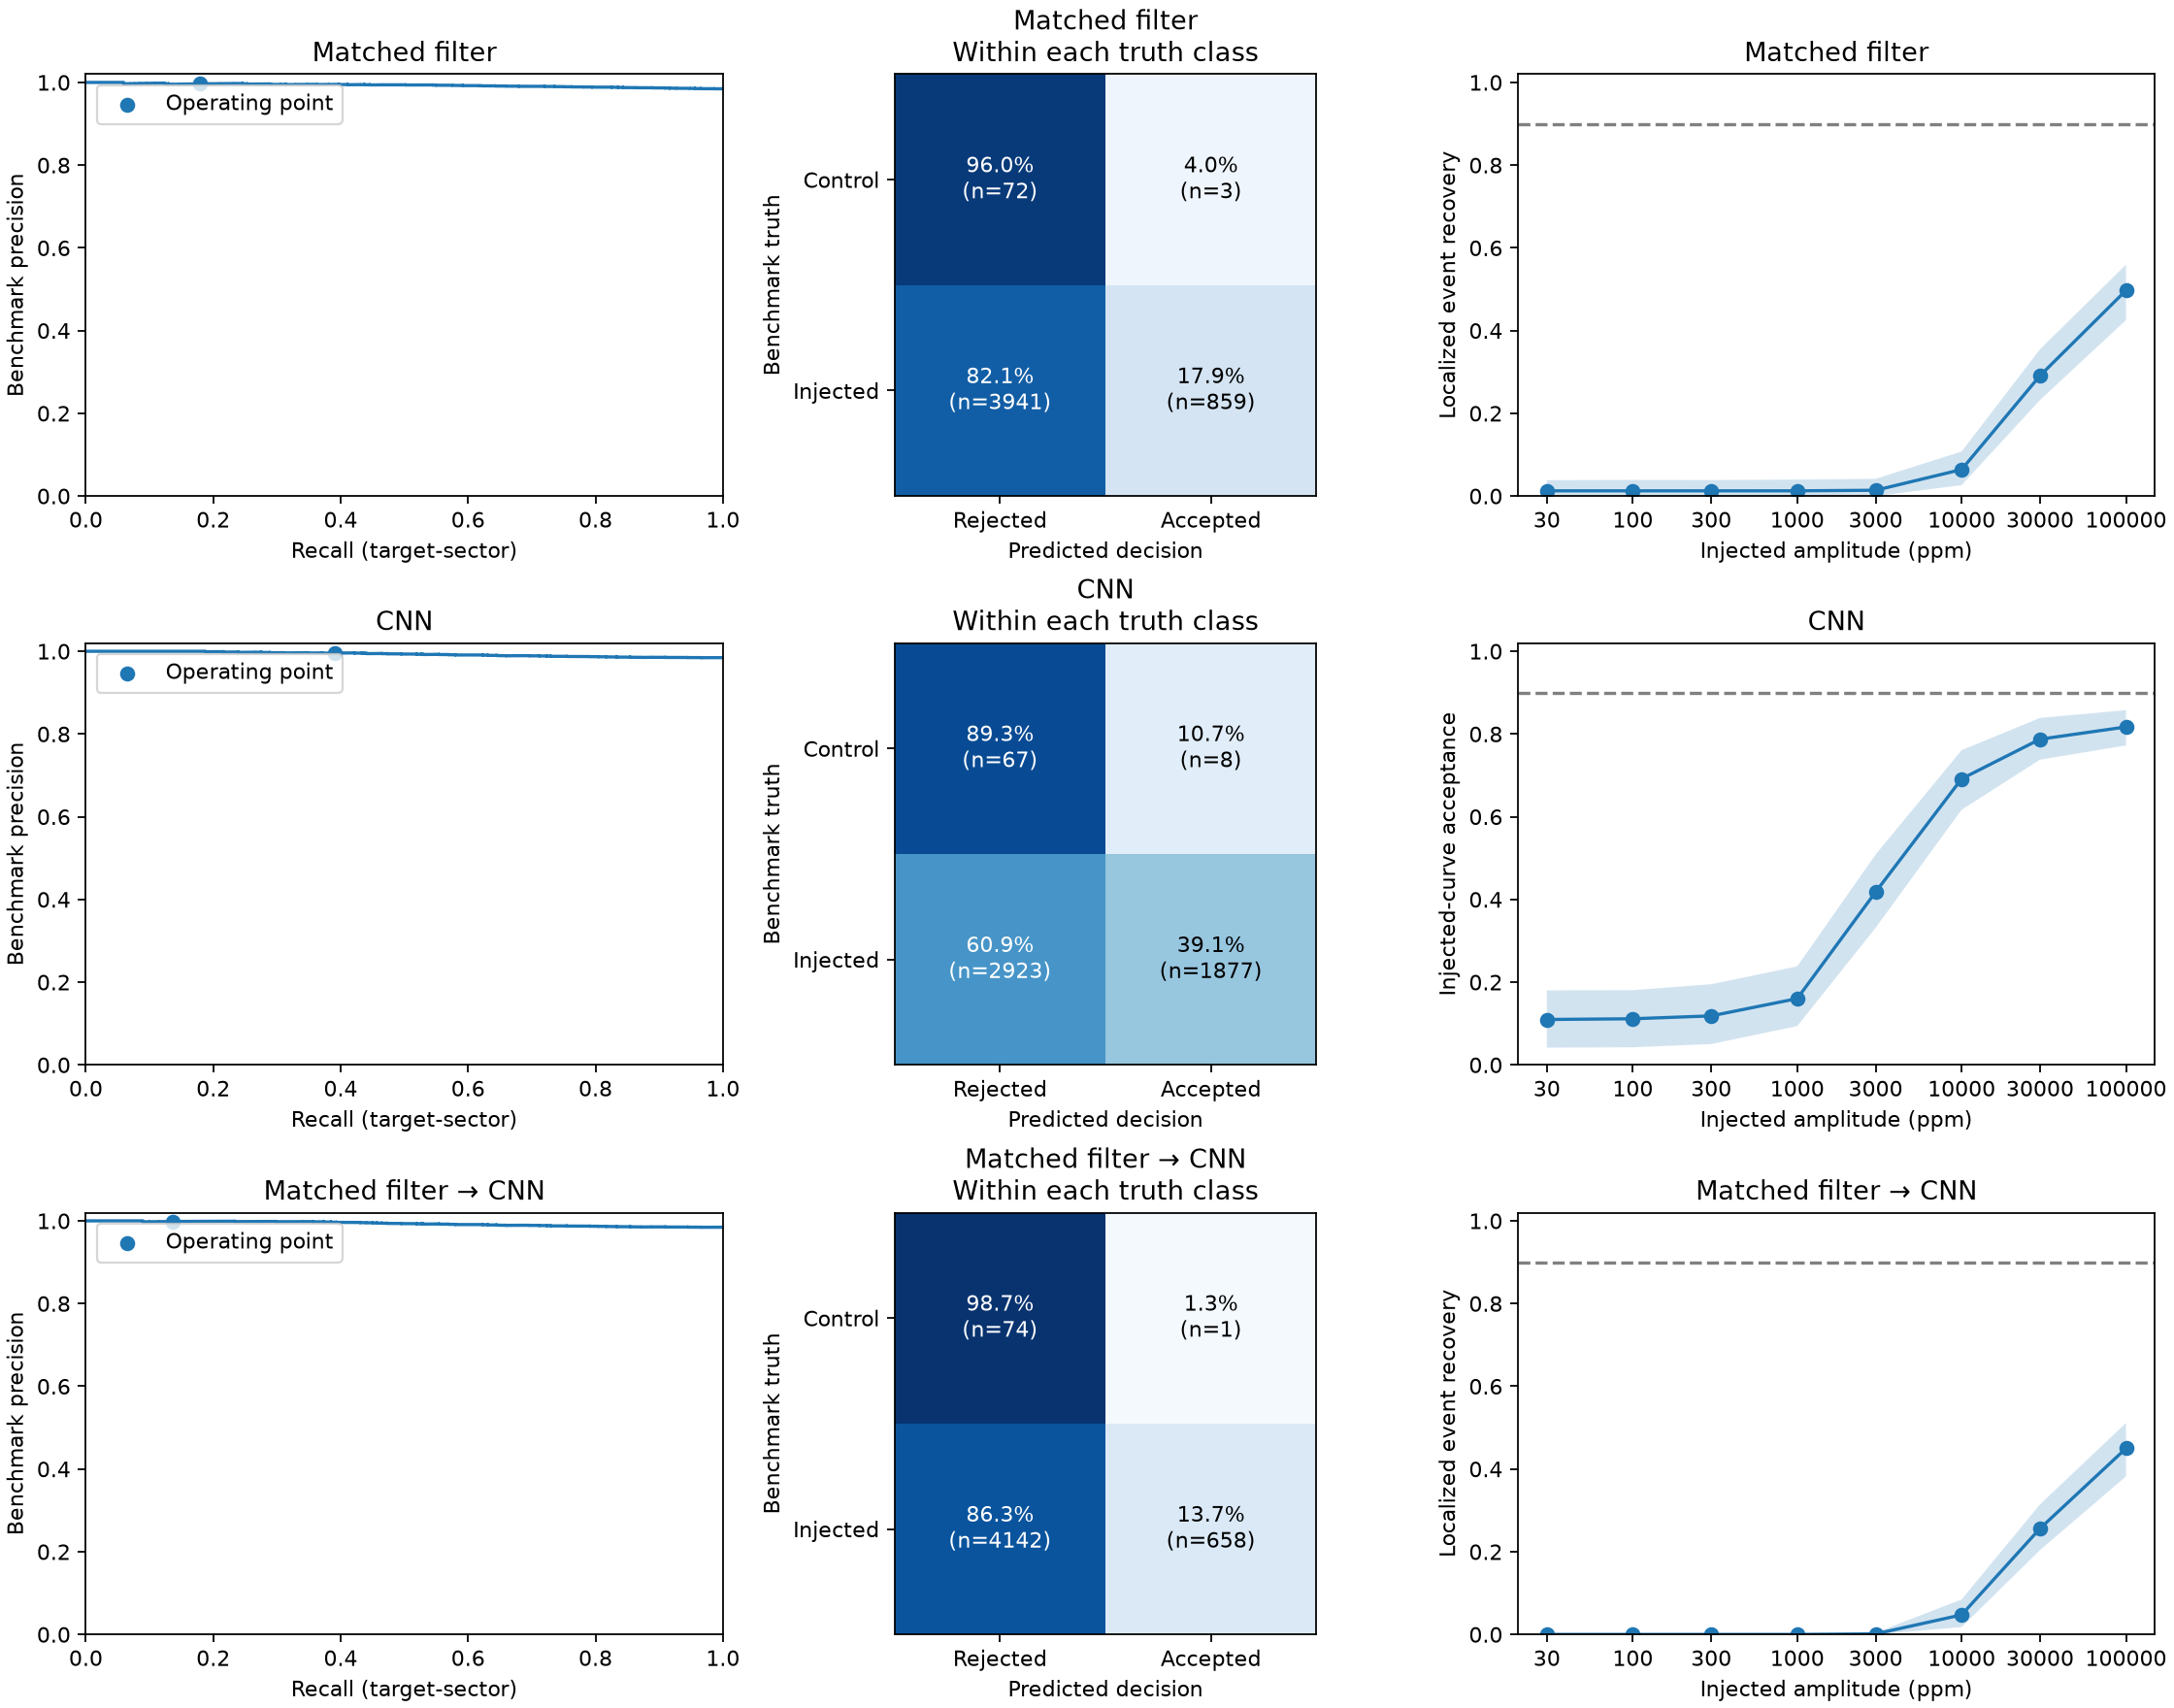

In [3]:
# Rebuild summaries/figures from saved scores, including older completed runs.
# No detector or CNN inference is repeated.
from searchlight.evaluation.simple import render
render(RESULTS)
sensitivity = load('amplitude_recovery')
labels = {'matched_filter': 'Matched filter', 'cnn': 'CNN',
          'combined': 'Matched filter → CNN' if run['pipeline_order'] == 'matched_filter_then_cnn' else 'CNN → matched filter'}
display(Image(filename=str(RESULTS / 'simple_evaluation.png')))


## Operating points and sequential gates

Thresholds are chosen on tuning targets only. All three confusion matrices use
the full test set. The combined PR curve sweeps the joint standardized threshold
margin; the operating point requires both fixed component gates. Stage counts
below show how many curves survive each gate in the configured sequence.


In [4]:
print('Component thresholds:', run['thresholds'])
composition = pd.DataFrame([{'split': split,
    'targets': len({r['group_id'] for r in scores if r['split'] == split}),
    'injected_examples': sum(r['truth'] == 1 for r in scores if r['split'] == split),
    'controls': sum(r['truth'] == 0 for r in scores if r['split'] == split)}
    for split in ['tuning', 'test']])
display(composition)
print('Confusion matrices: ROWS are benchmark truth; COLUMNS are predicted decisions.')
test_composition = composition.set_index('split').loc['test']
ratio = test_composition['injected_examples'] / test_composition['controls']
all_accepted_precision = test_composition['injected_examples'] / (test_composition['injected_examples'] + test_composition['controls'])
print(f'Test mixture: {ratio:g} injected curves per control. Accepting every curve would give '
      f'{all_accepted_precision:.1%} benchmark precision; this is not survey precision.')
decisions = []
for key, label in labels.items():
    tn, fp, fn, tp = np.asarray(metrics[key]['test']['confusion_matrix']).ravel()
    decisions.append({'method': label, 'controls_rejected': tn, 'controls_accepted': fp,
                      'injections_rejected': fn, 'injections_accepted': tp,
                      'all_rejected': fp+tp == 0, 'all_accepted': tn+fn == 0})
display(pd.DataFrame(decisions))
display(pd.DataFrame([{'method': label,
    'recall': metrics[key]['test']['recall'], 'benchmark_precision': metrics[key]['test']['precision'],
    'control_false_positive_fraction': metrics[key]['test']['false_positive_rate'],
    'recall_95pct': metrics[key]['test'].get('uncertainty', {}).get('intervals', {}).get('recall'),
    'precision_95pct': metrics[key]['test'].get('uncertainty', {}).get('intervals', {}).get('precision')}
    for key, label in labels.items()]))
for key, label in labels.items():
    print(label)
    display(pd.DataFrame(metrics[key]['test']['confusion_matrix'],
                         index=['Control truth', 'Injected truth'], columns=['Predicted rejected', 'Predicted accepted']))
    display(pd.DataFrame(metrics[key]['test']['confusion_row_normalized'],
                         index=['Control truth', 'Injected truth'],
                         columns=['Predicted rejected', 'Predicted accepted']).map(
                             lambda value: 'undefined' if value is None else f'{value:.1%}'))
attrition = load('attrition')
display(pd.DataFrame([{'split': split, 'order': ' → '.join(value['order']),
    'input': value['input_rows'], 'after_first_gate': value['after_first'],
    'after_second_gate': value['after_second']} for split, value in attrition.items()]))


Component thresholds: {'matched_filter': 262.2176771227893, 'cnn': 0.5394957918343134, 'combined': 0.0}


,split,targets,injected_examples,controls
0,tuning,25,1600,25
1,test,75,4800,75


Confusion matrices: ROWS are benchmark truth; COLUMNS are predicted decisions.
Test mixture: 64 injected curves per control. Accepting every curve would give 98.5% benchmark precision; this is not survey precision.


,method,controls_rejected,controls_accepted,injections_rejected,injections_accepted,all_rejected,all_accepted
0,Matched filter,72,3,3941,859,False,False
1,CNN,67,8,2923,1877,False,False
2,Matched filter → CNN,74,1,4142,658,False,False


,method,recall,benchmark_precision,control_false_positive_fraction,recall_95pct,precision_95pct
0,Matched filter,0.178958,0.996520,0.040000,"[0.13811979166666666, 0.22568229166666662]","[0.9937036078940841, 1.0]"
1,CNN,0.391042,0.995756,0.106667,"[0.34665625, 0.4412552083333333]","[0.9936584592127033, 0.9982248520710059]"
2,Matched filter → CNN,0.137083,0.998483,0.013333,"[0.11186979166666668, 0.16958333333333334]","[0.9957135149023638, 1.0]"


Matched filter


... (5 outputs left out)

Matched filter → CNN


,Predicted rejected,Predicted accepted
Control truth,74,1
Injected truth,4142,658


,Predicted rejected,Predicted accepted
Control truth,98.7%,1.3%
Injected truth,86.3%,13.7%


,split,order,input,after_first_gate,after_second_gate
0,tuning,matched_filter → cnn,1625,337,237
1,test,matched_filter → cnn,4875,862,659


## Amplitude sensitivity for all three methods

Amplitude follows the saved run convention, in ppm. Full runs use the reference
exposure-averaged peak, independent of whether that peak is sampled. CNN curves
count each injected light curve once; event curves count each periodic truth event.
CNN sensitivity measures classification acceptance; it cannot localize an event.
Matched-filter sensitivity requires a correctly located detection. The cascade
additionally requires CNN acceptance. All three use the same observable test
injections and whole-target bootstrap bands.

The limit is the lowest tested amplitude meeting the requested recall at that
and all higher tested levels. It is a point estimate, conditional on these
backgrounds, shapes, coverage and thresholds. A missing limit means the tested
grid did not establish one.


In [5]:
display(pd.DataFrame([{'method': labels[key], 'measure': value['measure'],
    'requested_recall': value['required_recall'],
    'minimum_tested_amplitude_ppm': value['minimum_tested_amplitude_ppm']}
    for key, value in sensitivity['by_component'].items()]))
for key, value in sensitivity['by_component'].items():
    print(labels[key], '—', value['measure'])
    display(pd.DataFrame(value['rows']))
test_events = [e for e in events if e['split'] == 'test']
print('Test event coincidences with uninjected-control candidates:',
      sum(e.get('control_has_candidate', False) for e in test_events))
print('Inspect coincidences before attributing recovery to the injection.')

print('Amplitude convention:', manifest.get('metadata', {}).get('amplitude_convention', 'Maximum sampled exposure-averaged signal'))
for split in ['tuning', 'test']:
    rows = [e for e in events if e['split'] == split]
    print(f"{split}: {len(rows)} truth events; {sum(e['observable'] for e in rows)} adequately sampled")


,method,measure,requested_recall,minimum_tested_amplitude_ppm
0,Matched filter,Localized event recovery,0.9,None
1,CNN,Injected-curve acceptance,0.9,None
2,Matched filter → CNN,Localized event recovery,0.9,None


Matched filter — Localized event recovery


,amplitude_ppm,events,targets,recovered,recall,lower,upper
0,30.0,718,75,9,0.012535,0.000000,0.038355
1,100.0,718,75,9,0.012535,0.000000,0.038911
2,300.0,718,75,9,0.012535,0.000000,0.038576
3,1000.0,718,75,9,0.012535,0.000000,0.039778
4,3000.0,718,75,10,0.013928,0.000000,0.041609
5,10000.0,718,75,46,0.064067,0.026281,0.107609
6,30000.0,718,75,209,0.291086,0.232119,0.354939
7,100000.0,718,75,357,0.497214,0.425346,0.559506


CNN — Injected-curve acceptance


,amplitude_ppm,events,targets,recovered,recall,lower,upper
0,30.0,574,75,63,0.109756,0.041665,0.180216
1,100.0,574,75,64,0.111498,0.042548,0.180563
2,300.0,574,75,68,0.118467,0.050428,0.195079
3,1000.0,574,75,92,0.160279,0.093634,0.238108
4,3000.0,574,75,240,0.418118,0.331555,0.508790
5,10000.0,574,75,397,0.691638,0.616811,0.760846
6,30000.0,574,75,452,0.787456,0.738012,0.838827
7,100000.0,574,75,469,0.817073,0.772402,0.857657


Matched filter → CNN — Localized event recovery


,amplitude_ppm,events,targets,recovered,recall,lower,upper
0,30.0,718,75,0,0.000000,0.000000,0.000000
1,100.0,718,75,0,0.000000,0.000000,0.000000
2,300.0,718,75,0,0.000000,0.000000,0.000000
3,1000.0,718,75,0,0.000000,0.000000,0.000000
4,3000.0,718,75,1,0.001393,0.000000,0.004323
5,10000.0,718,75,34,0.047354,0.017807,0.084592
6,30000.0,718,75,184,0.256267,0.204038,0.314609
7,100000.0,718,75,323,0.449861,0.382102,0.511339


Test event coincidences with uninjected-control candidates: 80
Inspect coincidences before attributing recovery to the injection.
Amplitude convention: Reference exposure-averaged peak, independent of coverage
tuning: 2136 truth events; 2008 adequately sampled
test: 6072 truth events; 5744 adequately sampled


## Injected/control examples

Choose `EXAMPLE` to inspect other saved test injections. The second panel shows
only the added signal. Saved observed timestamps include gaps. Background
candidates and missed high-amplitude injections deserve inspection.

tic220502315-sector1-cadence120-shape0-amp7 Recovered: False Observable: True


,method,score,threshold,curve_accepted
0,Matched filter,506.756262,262.217677,True
1,CNN,0.993367,0.539496,True
2,Matched filter → CNN,0.155998,0.000000,True


Curve acceptance and localized event recovery are different measurements.


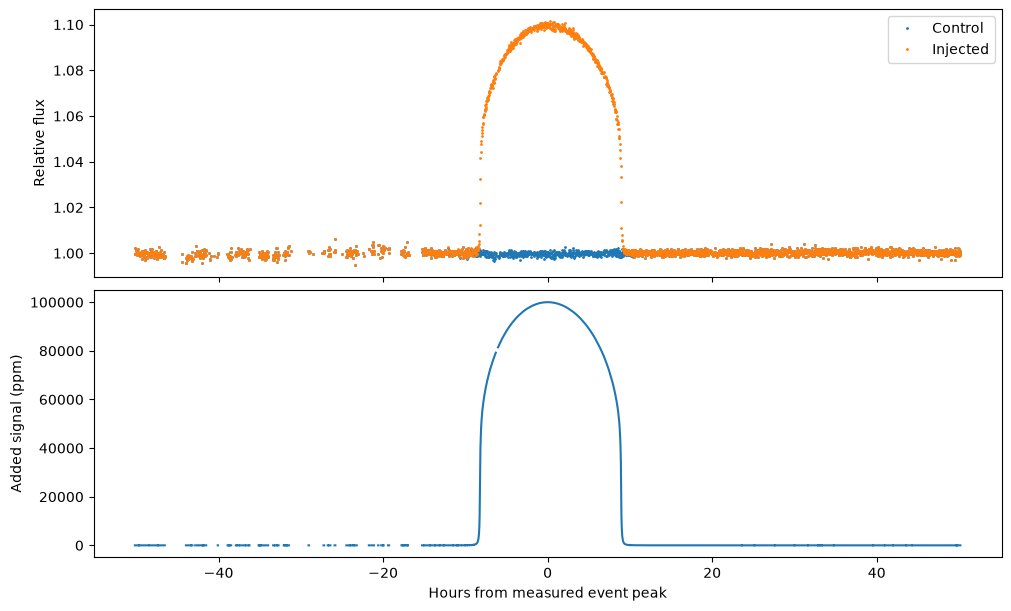

In [6]:
from searchlight.evaluation.preprocessing import read_lightcurve
samples = {s['sample_id']: s for s in manifest['samples']}
examples = [e for e in test_events if np.isclose(e['amplitude'] * 1e6, max(r['amplitude_ppm'] for r in sensitivity['rows']), rtol=1e-12)]
# Inspect strong, observable event misses first; these are diagnostic examples.
misses = [e for e in examples if e['observable'] and not e['combined_recovered']]
examples = misses or examples
EXAMPLE = 0
if examples:
    event = examples[EXAMPLE]
    sample = samples[event['sample_id']]
    injected = read_lightcurve(sample['source'])
    control = read_lightcurve(samples[sample['parent_id']]['source'])
    t = (injected.time - event['time']) * 24
    region = np.abs(t) <= 3 * event['duration_days'] * 24
    norm = np.nanmedian(control.flux)
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')
    ax[0].plot(t[region], control.flux[region] / norm, '.', ms=2, label='Control')
    ax[0].plot(t[region], injected.flux[region] / norm, '.', ms=2, label='Injected')
    ax[0].legend(); ax[0].set_ylabel('Relative flux')
    ax[1].plot(t[region], (injected.flux[region] - control.flux[region]) / norm * 1e6)
    ax[1].set(xlabel='Hours from measured event peak', ylabel='Added signal (ppm)')
    print(sample['sample_id'], 'Recovered:', event['combined_recovered'], 'Observable:', event['observable'])
    decision = next(row for row in scores if row['sample_id'] == sample['sample_id'])
    display(pd.DataFrame([{'method': labels[key], 'score': decision[key]['score'],
                           'threshold': run['thresholds'][key], 'curve_accepted': decision[key]['accepted']}
                          for key in labels]))
    print('Curve acceptance and localized event recovery are different measurements.')
    plt.show()

In [7]:
# Compact reproducibility record; detailed provenance is in results/run.json.
print('Physics:', run['dataset_metadata'].get('simulator'))
print('CNN:', run.get('cnn', {}).get('checkpoint_sha256'))
print('Templates:', run['template_sha256'])
print('Preprocessing:', run['preprocessing'])
print('Figures:', RESULTS / 'simple_evaluation.pdf')

print('CPU processes:', run.get('workers', 1), 'CNN processes:', run.get('cnn', {}).get('workers', 1))

print('Saved proposal distributions:', manifest.get('metadata', {}).get('sampling_distributions', 'not recorded in this historical run'))


Physics: {'selflensing': {'version': '0.0.1', 'direct_url': {'url': 'ssh://git@github.com/COBALT-lensing/py-self-lensing.git', 'vcs_info': {'vcs': 'git', 'commit_id': 'bfb8043aca508abff5174849a3fd8cb7ea561e7e'}}, 'commit_id': 'bfb8043aca508abff5174849a3fd8cb7ea561e7e'}, 'rustlens': {'version': '0.6.0', 'direct_url': None, 'commit_id': None}, 'jaxoplanet': {'version': '0.2.0', 'direct_url': None, 'commit_id': None}}
CNN: 36fa76961e6fdb95b4dbe1d6b8a86c9397b038ca3b3d16c0518c857399516a23
Templates: dd3cd03f5fca71493c5bfe31391a61279e943753cc8dd878c3259434f724eb77
Preprocessing: {'flux_product': 'PDCSAP_FLUX', 'quality_bitmask': -1, 'trim_start_hours': 0, 'normalize': True, 'detrend_window_days': None, 'gap_factor': 1.5, 'min_segment_points': 3, 'exposure_seconds': None}
Figures: /home/anm1u24/Code/astrosearchlight/evaluation_runs/full-evaluation-002/results/simple_evaluation.pdf
CPU processes: 1 CNN processes: 8
Saved proposal distributions: not recorded in this historical run
